# Metadata Construction

First notebook in the data-object creation pipeline. Consolidates all sample-level metadata into a single parquet file consumed by all downstream notebooks.

The SCI dataset spans **9 participating laboratories** across 6 instrument configurations (6 × Astral, 3 × timsTOF). Each lab independently acquired single-cell proteomics data from the same frozen cell stocks (K562, HEK293T) plus their own site-specific QC and HeLa standards. Metadata was captured from two independent sources:

| Source | Format | Content |
|---|---|---|
| **SDRF files** | `SDRF.xlsx` per lab | Acquisition metadata: sample identity, gradient time, plate number, injection timestamps |
| **cellenONE reports** | `Reordered_*_isolated.xls` per plate | Cell dispensing metadata: XY plate position, morphological measurements (diameter, elongation, circularity), QC flags, image paths |

This notebook merges both sources on plate position coordinates and applies a multi-step parsing and imputation pipeline to produce a single, analysis-ready metadata table.

## Imports

`SCI_read` handles raw file ingestion; `SCI_parse` handles column normalisation and imputation. Plot utilities draw the QC overview figures.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
import os
from pathlib import Path

from glob import glob

from SCI_py.metadata import read as SCI_read
from SCI_py.metadata import parse as SCI_parse

from SCI_py.plot.constants import CONDITION_COLORS, LAB_COLORS
from SCI_py.plot.metadata import plot_metadata_overview, plot_cell_qc_overview

## 0. Path Configuration

Input directories point to the compute node (`conode53`) where raw metadata files reside. The output directory defaults to `Data/` relative to the notebook and can be overridden with the `SCI_DATA_DIR` environment variable.

In [2]:
# Set the paths
ROOT_SDRF_IN = '/public/conode53/sam/SCI_paper/metadata'
ROOT_CELLENONE_IN = '/public/conode53/sam/SCI_paper/cellenONE/cellenONE_Reports'

# OUTPUT PATH
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

Output directory: /home/sam/SCI/SCI/Data


## 1. Metadata File Construction

Four operations are chained to build the final metadata table. Each is described in detail below.

---

### 1.1 Read SDRF files — `SCI_read.read_SDRF`

One `SDRF.xlsx` file exists per lab, stored in a sub-directory named by plate ID (e.g. `Wyss_Astral_1/SDRF.xlsx`). All files are concatenated and the following transformations applied:

- **Sample name derivation** — each lab used a different filename convention, so a plate-specific converter function extracts the canonical sample name from `comment[data file]`. For example, Broad files with `_redo_` in the name require different splitting than IMP timsTOF files, which embed extra run-level tokens.
- **Plate number mapping** — `comment[Plate Number]` is populated from a lookup table (`LAB_TO_PLATENR`) because it is not reliably present in all SDRF files.
- **Well coordinate conversion** — `comment[X position]` is stored as a letter (A–P) in the SDRF; it is converted to a 1-based integer. A `WellName` column in `R{row}-C{col}` notation is computed from the (X, Y) pair, accounting for the plate's Y-axis inversion (Y = 1 is the bottom row → R24).
- **Reinjection annotation** — two sites reinjected selected cells: Wyss reinjections are identified from a supplementary CSV (`CSI_Plate4run3.csv`); Broad reinjections are identified by the string `"redo"` in the filename. When both an original and a reinjection exist for the same cell, the reinjection is kept and the original dropped.
- **BYU source-name correction** — a known pipetting error caused BYU to swap `"Site specific QC"` and `"Site specific blanks"` well labels; these are silently corrected here.

---

### 1.2 Read cellenONE reports — `SCI_read.read_cellenONE`

The cellenONE dispenser writes one isolation report per plate × cell-type combination (`Reordered_*_isolated.xls`). These are scanned recursively, and for each file:

- Plate number is parsed from the parent directory name.
- Cell type (sample type) is parsed from the sub-directory name.
- An `image_path` column is constructed pointing to the per-cell brightfield image.
- Position columns (`XPos`, `YPos`) are renamed to the SDRF convention (`comment[X position]`, `comment[Y position]`) to enable the merge.

---

### 1.3 Merge and well-level QC annotations

The SDRF and cellenONE tables are joined on `comment[X position]`, `comment[Y position]`, and `comment[Plate Number]` (left join on SDRF). This attaches morphological measurements — **diameter**, **elongation**, **circularity** — and cell-dispensing QC flags to every acquisition row.

Manual per-well annotations from plate preparation notes are then applied as four boolean columns:

| Flag | Meaning |
|---|---|
| `Dying` | Cell showed morphological signs of death at dispensing |
| `Dividing` | Cell was caught mid-division (two nuclei or dumbbell shape) |
| `Doublet` | Two cells co-dispensed into one well |
| `CellInBlank` | A cell was accidentally dispensed into a designated blank well |

Annotations cover plates 2–10, 13, and 14. Plates 1, 11, and 12 have only free-text notes (recorded in `PLATE_NOTES`) and are not annotated at the well level.

---

### 1.4 Metadata parsing pipeline — `SCI_parse.parse_metadata_columns`

An 8-step pipeline is applied to the merged table:

1. **Sample name normalisation** — convert to lowercase for consistent joining with search results.

2. **Temporal column parsing** — three raw datetime strings (`comment[plate arrival]`, `comment[Gradient time]`, `comment[thawing timepoint]`) are each split into three derived columns:
   - `_date` — date floored to midnight
   - `_time` — decimal hours (e.g. 14.5 = 14:30:00)
   - `_datetime` — full timestamp

3. **Derived identifier columns**
   - `instrument_type` — extracted from the plate ID (e.g. `"Astral"`, `"timsTOF"`)
   - `sample_id` — globally unique key: `sample_name|plate_id`
   - `plate_idx` — anonymised lab label used in figures (e.g. `"Astral_1"`, `"timsTOF_2"`)

4. **Source name normalisation** — internal dispensing labels (`"Cell A"`, `"Cell B"`) are mapped to the biological cell line names (`"K562"`, `"HEK293T"`).

5. **Injection order** — a normalised injection order in [0, 1] is computed within each plate from `comment[Gradient time]_datetime`. Samples with missing timestamps receive the plate-level median. This is used to model and correct run-order effects downstream.

6. **Missing value imputation** — three strategies applied in sequence:
   - *Scalar sentinels* — numeric fields (morphology measurements, plate coordinates) are filled with `-1`; SDRF controlled-vocabulary text fields with `"not applicable"` or `"not available"`.
   - *Source-name lookups* — SDRF characteristic columns (organism, organism part, cell type, disease, cell line) are fully overwritten from lookup tables keyed on `source name`, ensuring consistency across all labs.
   - *Plate-specific imputation* — `KI_Astral_2` lacks gradient time data; dates are copied from the thawing timepoint and times are matched by sample name from the paired `KI_Astral_1` plate, with datetimes reconstructed from the imputed components.

7. **Type enforcement** — X/Y positions cast to `int`; date/time columns to `str`; QC flag columns (`Reinjection`, `Doublet`, `Dividing`, `Dying`, `CellInBlank`) to `bool`.

8. **Duplicate column removal** — some SDRF files introduce a spurious `comment[plate arrival].1` column during concatenation; it is dropped here.

In [3]:
# Read the SDRF files and parse some columns
sdrf = SCI_read.read_SDRF(
    ROOT_SDRF_IN
)
# Read the cellenONE metadata files
isolated_df = SCI_read.read_cellenONE(ROOT_CELLENONE_IN)

# Merge the two metadata sources
metadata = sdrf.merge(
    isolated_df,
    on=['comment[X position]', 'comment[Y position]', 'comment[Plate Number]'],
    how='left'
)

# Add annotations from the plate preparation documentation
metadata = SCI_read.add_docx_annotations(metadata)

# Parse
metadata = SCI_parse.parse_metadata_columns(metadata)

/home/sam/SCI/SCI/SCI_py/SCI_py/metadata/parse.py:232: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("plate_id", group_keys=False).apply(_plate_order)


## 2. Visualisation

Two QC figures are generated to verify the metadata before saving:

- **`plot_metadata_overview`** — shows sample counts per lab and condition, plate layouts coloured by source name, and injection-order distributions. Useful for spotting missing plates or mislabelled conditions.
- **`plot_cell_qc_overview`** — shows distributions of morphological measurements (diameter, elongation, circularity) and the prevalence of each QC flag (dying, dividing, doublet, blank) per plate. Used to assess dispensing quality across sites.

/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plate_order, rotation=45, ha='right')
/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(instrument_counts.index, rotation=35, ha='right')
/home/sam/SCI/SCI/SCI_py/SCI_py/plot/metadata.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


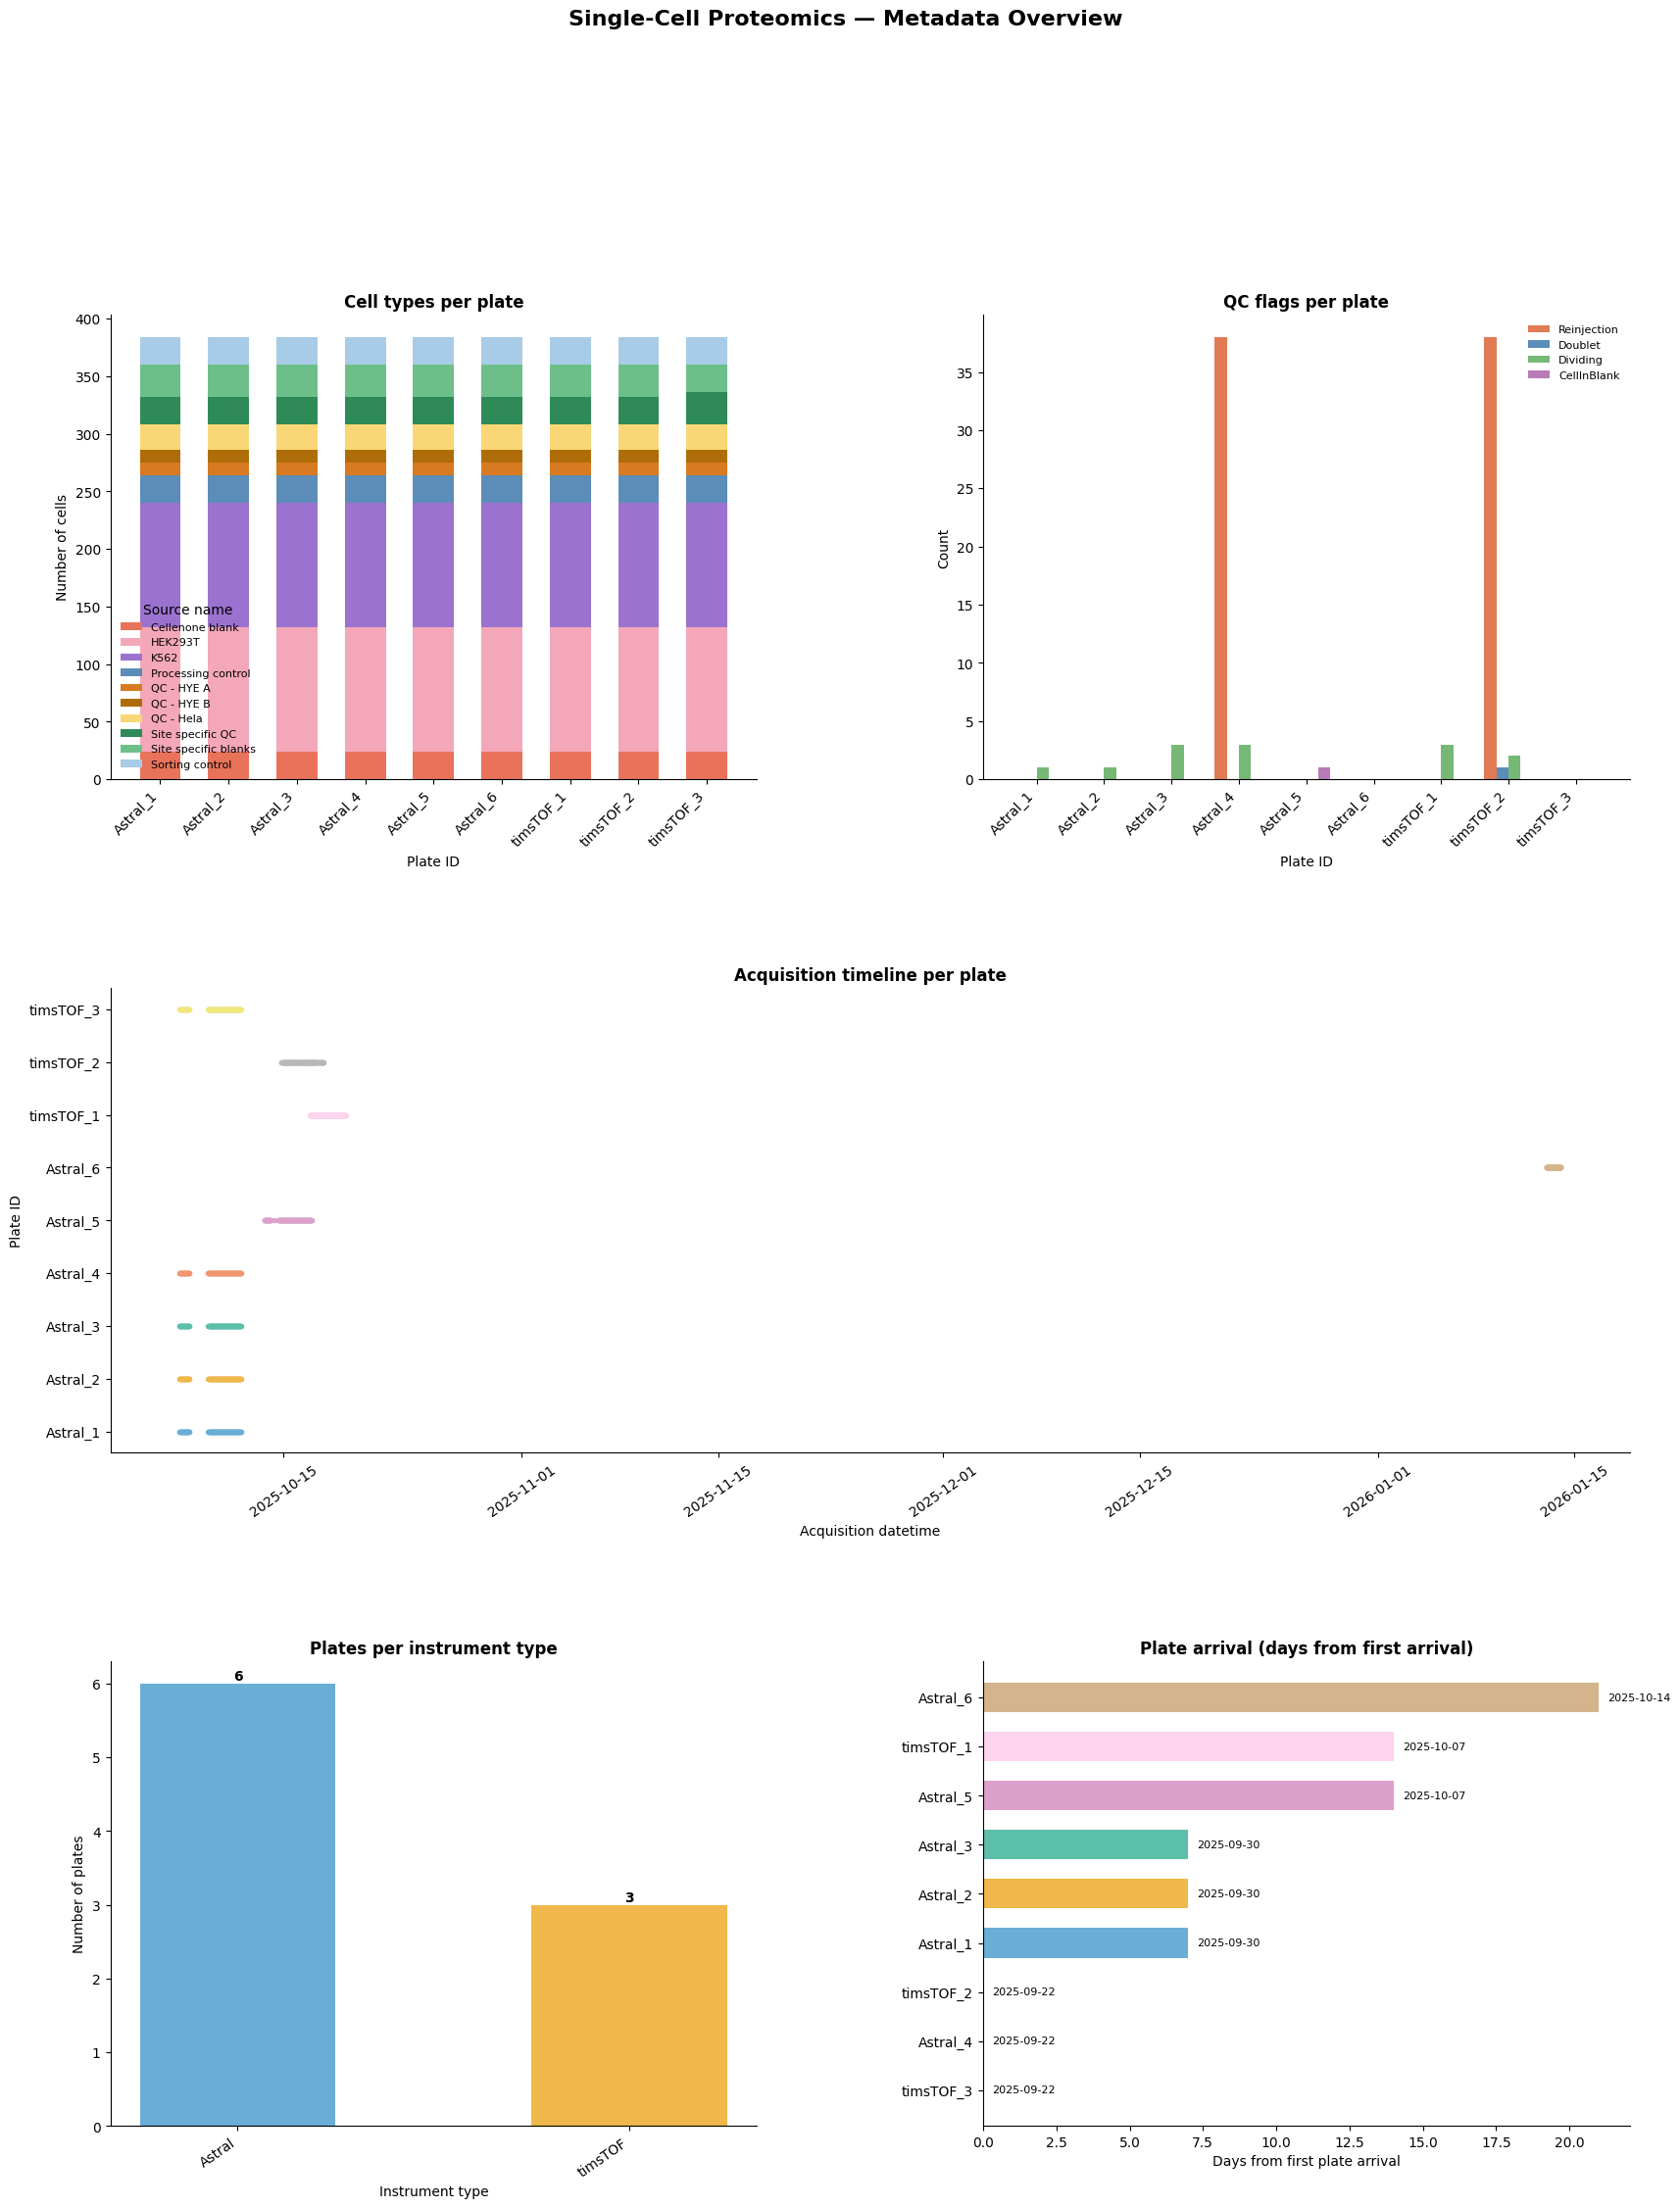

In [4]:
fig = plot_metadata_overview(
    metadata,
    save_path=False
)

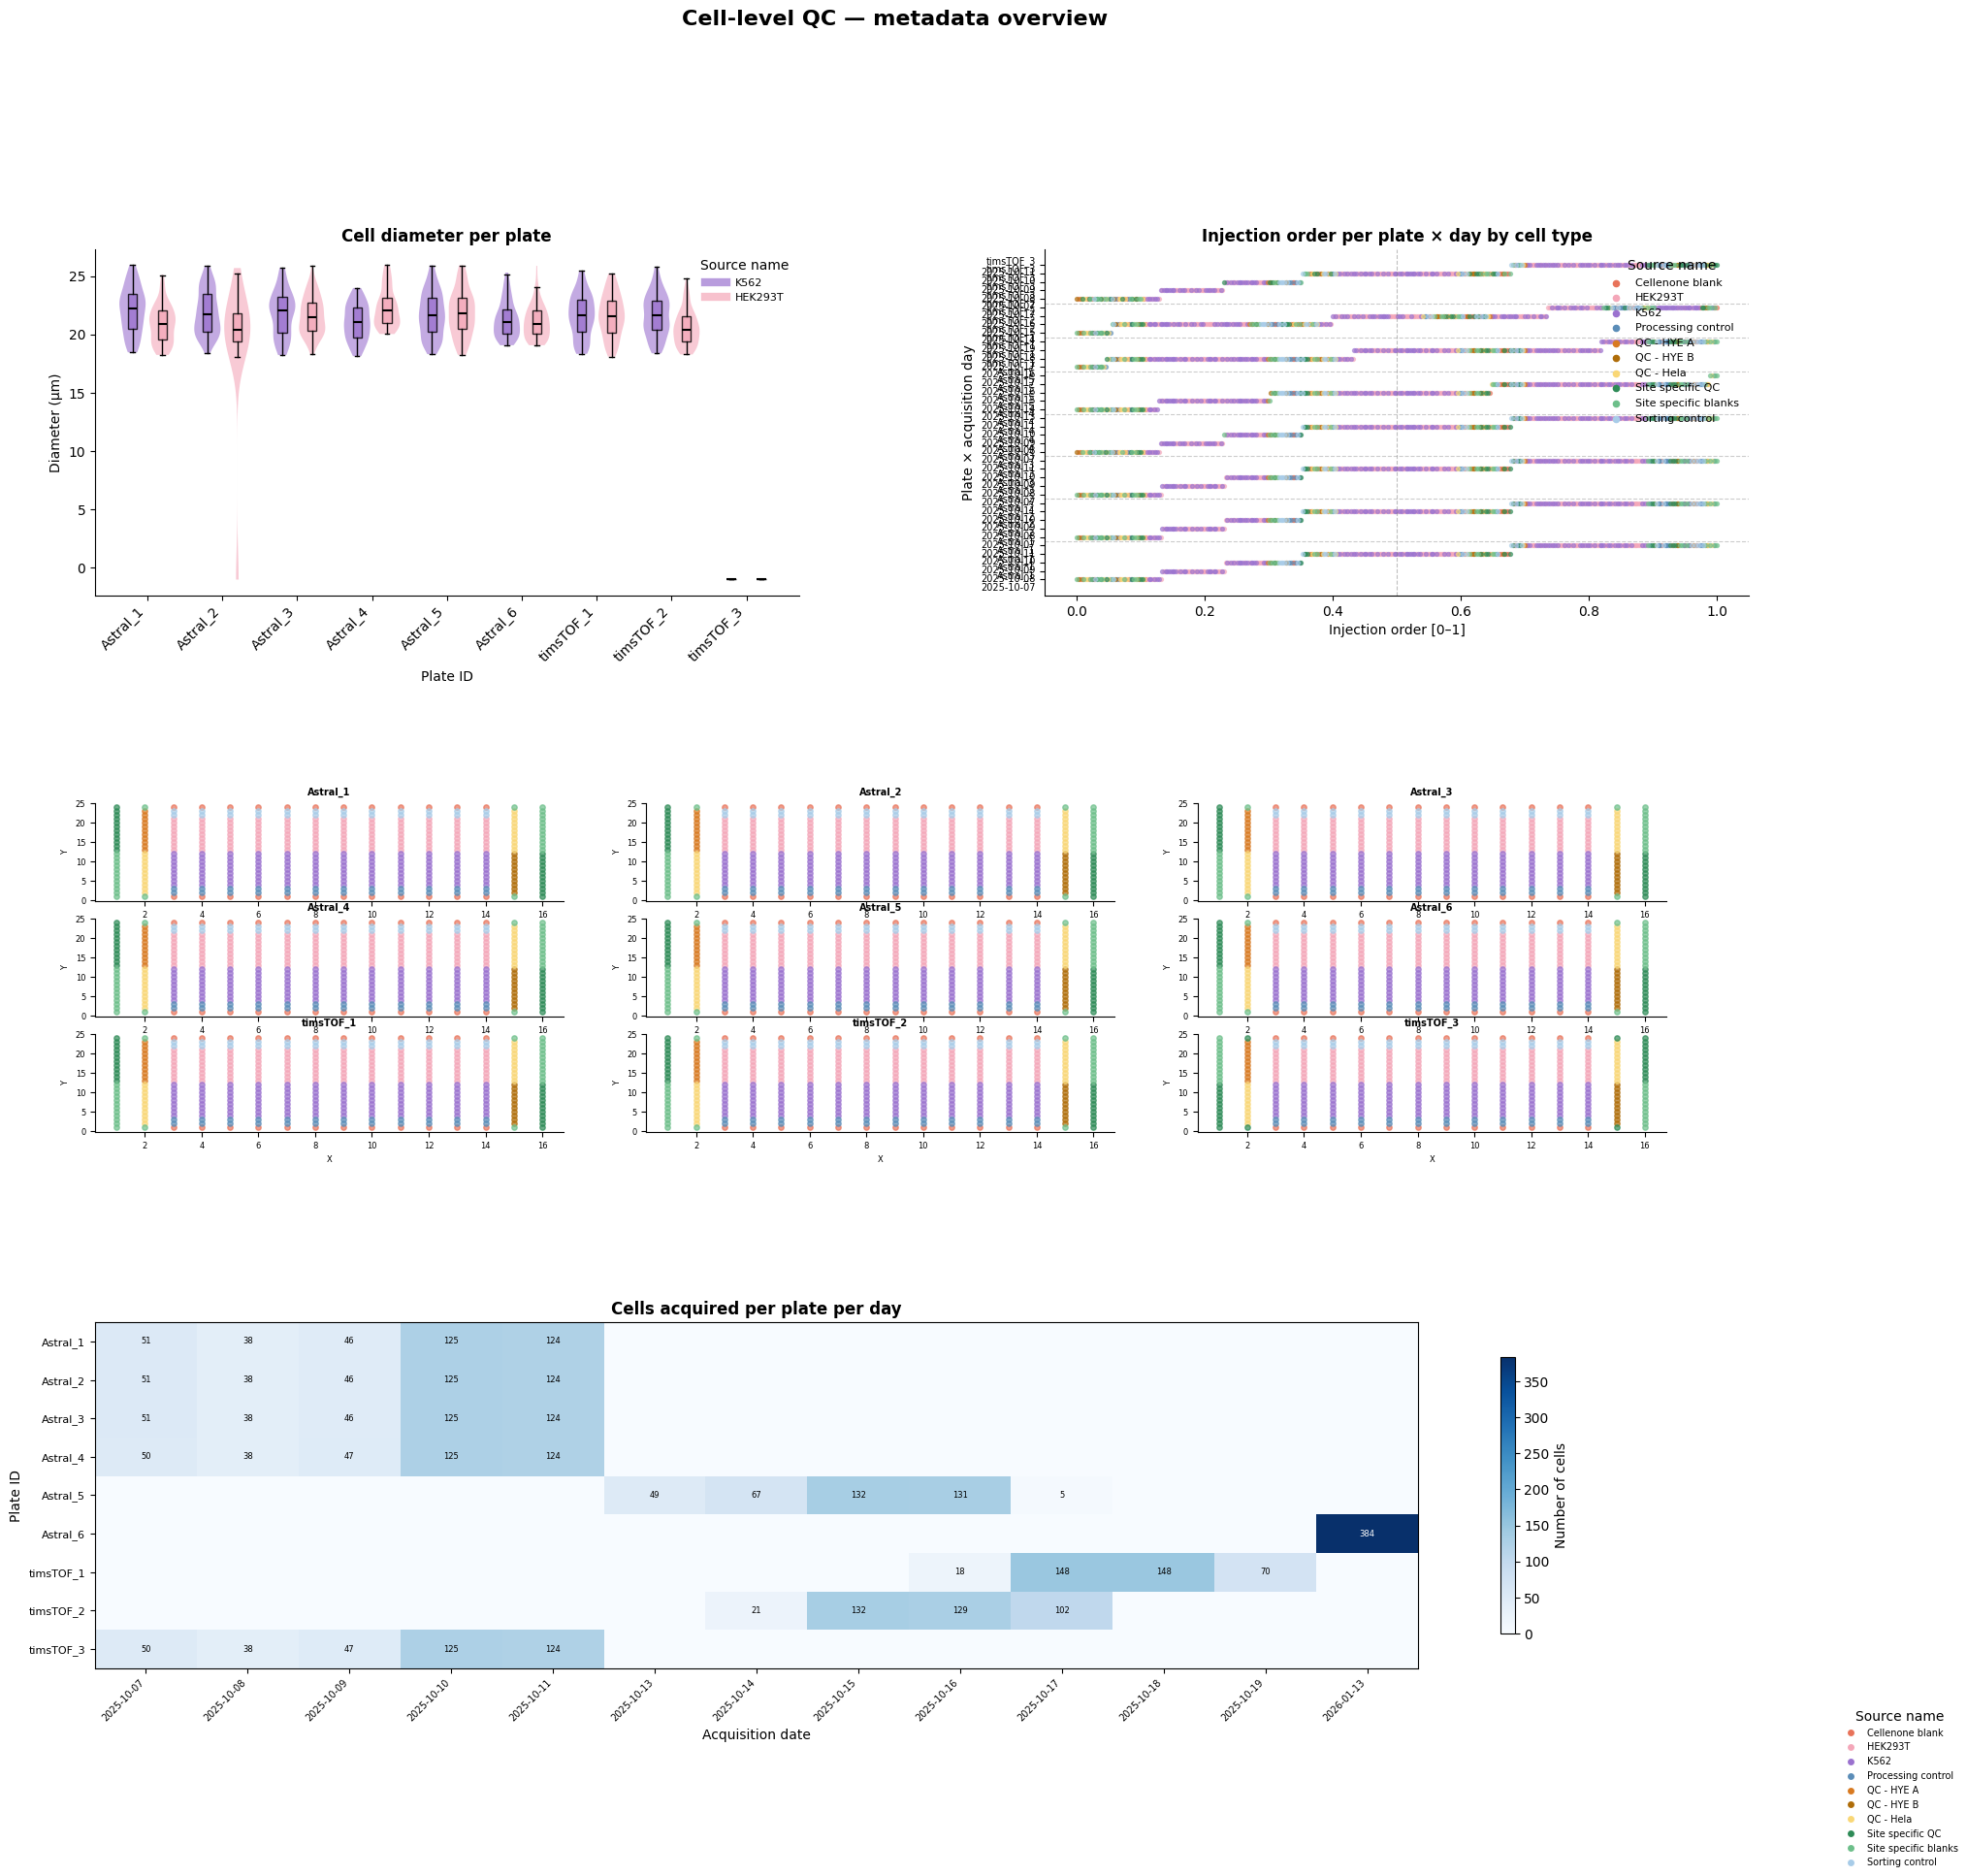

In [5]:
fig = plot_cell_qc_overview(
    metadata, 
    save_path=False
)

## 3. Save

Write the completed metadata table to `Data/metadata/metadata.parquet`. Parquet is used rather than CSV to preserve column dtypes (bool flags, timestamps) exactly and to enable fast predicate pushdown when loading subsets in downstream notebooks.

In [6]:
METADATA_OUT = os.path.join(ROOT_OUT, 'metadata')
Path(METADATA_OUT).mkdir(parents=True, exist_ok=True)

metadata.to_parquet(
    os.path.join(
        METADATA_OUT,
        'metadata.parquet'
    )
)